<a href="https://colab.research.google.com/github/surajguptacr7/MLproject/blob/main/ecg_arrhythmia_detection_1d_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

%pip install -q wfdb numpy pandas scipy scikit-learn matplotlib seaborn torch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.6 MB/s eta 0:00:00


In [ ]:

import os
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/content/mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

# Download the complete database
wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

print("Dataset download complete!")

# List downloaded ECG records
records = sorted([
    filename[:-4]
    for filename in os.listdir(DATA_DIR)
    if filename.endswith(".dat")
])

print("Number of records:", len(records))
print("First few records:", records[:10])


Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

Signal shape: (650000, 2)
Sampling frequency: 360
Available leads: ['MLII', 'V5']
Number of annotations: 2274


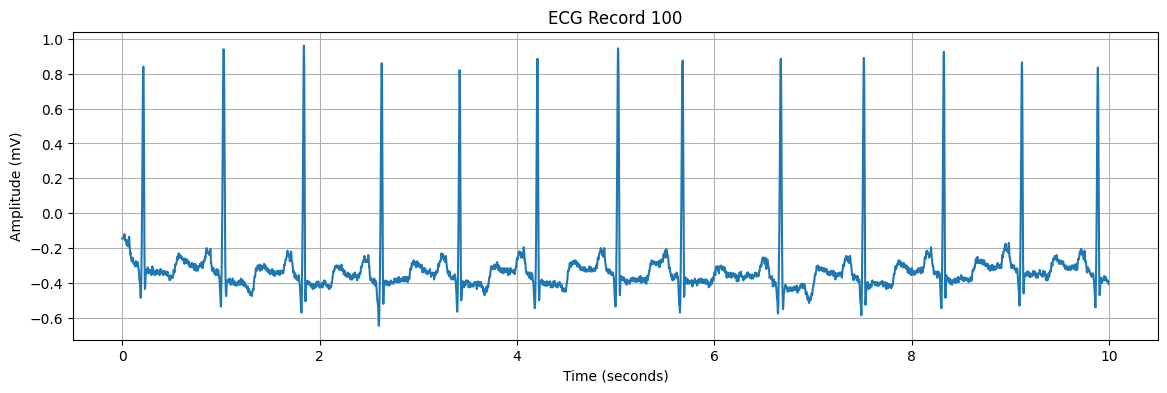

In [ ]:

record_id = "100"

record = wfdb.rdrecord(
    os.path.join(DATA_DIR, record_id)
)

annotation = wfdb.rdann(
    os.path.join(DATA_DIR, record_id),
    "atr"
)

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Available leads:", record.sig_name)
print("Number of annotations:", len(annotation.sample))

# Plot the first 10 seconds of the first lead
signal = record.p_signal[:, 0]
fs = record.fs
seconds = 10

plt.figure(figsize=(14, 4))
plt.plot(
    np.arange(int(seconds * fs)) / fs,
    signal[:int(seconds * fs)]
)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title(f"ECG Record {record_id}")
plt.grid(True)
plt.show()


In [ ]:

# STEP 3: Extract ECG heartbeat segments and assign labels

import wfdb
import numpy as np
import os
from collections import Counter

# MIT-BIH beat annotation groups
NORMAL_SYMBOLS = {"N", "L", "R", "e", "j"}
ABNORMAL_SYMBOLS = {"A", "a", "J", "S", "V", "E", "F", "r", "n", "/", "f", "Q"}

# Segment window around each annotated heartbeat
BEFORE = int(0.2 * 360)  # 72 samples before
AFTER  = int(0.4 * 360)  # 144 samples after
SEGMENT_LENGTH = BEFORE + AFTER  # 216 samples

X_list = []
y_list = []
record_ids = []

# Use only records that have all required files
records = sorted([
    f[:-4] for f in os.listdir(DATA_DIR)
    if f.endswith(".hea")
])

for record_id in records:
    try:
        record = wfdb.rdrecord(os.path.join(DATA_DIR, record_id))
        annotation = wfdb.rdann(
            os.path.join(DATA_DIR, record_id), "atr"
        )

        # Use the first ECG channel
        signal = record.p_signal[:, 0]

        for sample, symbol in zip(annotation.sample, annotation.symbol):
            if symbol in NORMAL_SYMBOLS:
                label = 0
            elif symbol in ABNORMAL_SYMBOLS:
                label = 1
            else:
                continue  # Ignore non-beat or unsupported annotations

            start = sample - BEFORE
            end = sample + AFTER

            # Skip beats too close to the recording boundaries
            if start < 0 or end > len(signal):
                continue

            beat = signal[start:end]

            if len(beat) != SEGMENT_LENGTH:
                continue

            # Normalize each segment for stable model training
            beat = beat.astype(np.float32)
            beat = (beat - beat.mean()) / (beat.std() + 1e-8)

            X_list.append(beat)
            y_list.append(label)
            record_ids.append(record_id)

    except Exception as error:
        print(f"Skipping record {record_id}: {error}")

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.int64)
record_ids = np.array(record_ids)

print("Heartbeat data shape:", X.shape)
print("Labels shape:", y.shape)
print("Normal beats (0):", int(np.sum(y == 0)))
print("Abnormal beats (1):", int(np.sum(y == 1)))
print("Unique records:", len(np.unique(record_ids)))
print("Segment length:", SEGMENT_LENGTH)


Heartbeat data shape: (109460, 216)
Labels shape: (109460,)
Normal beats (0): 90600
Abnormal beats (1): 18860
Unique records: 48
Segment length: 216


In [ ]:

# STEP 4: Patient-wise train / validation / test split

# A commonly used record partition, adjusted to keep 201 and 202 together.
train_records = {
    "101", "106", "108", "109", "112", "114", "115", "116",
    "118", "119", "122", "124", "201", "202", "203", "205",
    "207", "208", "209", "215", "220", "223", "230"
}

test_records = {
    "100", "103", "105", "111", "113", "117", "121", "123",
    "200", "210", "212", "213", "214", "219", "221", "222",
    "228", "231", "232", "233", "234"
}

# Hold out some complete training recordings for validation.
validation_records = {
    "108", "114", "118", "203", "209"
}

train_records = train_records - validation_records

train_mask = np.isin(record_ids, list(train_records))
val_mask = np.isin(record_ids, list(validation_records))
test_mask = np.isin(record_ids, list(test_records))

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape, Counter(y_train))
print("Validation:", X_val.shape, Counter(y_val))
print("Testing:", X_test.shape, Counter(y_test))

# Verify there is no overlap between splits
assert train_records.isdisjoint(validation_records)
assert train_records.isdisjoint(test_records)
assert validation_records.isdisjoint(test_records)

print("Patient/record split checks passed!")


Training: (41238, 216) Counter({np.int64(0): 37038, np.int64(1): 4200})
Validation: (11903, 216) Counter({np.int64(0): 10874, np.int64(1): 1029})
Testing: (47559, 216) Counter({np.int64(0): 42182, np.int64(1): 5377})
Patient/record split checks passed!


In [10]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cpu


In [11]:

# Convert ECG arrays to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# DataLoaders allow mini-batch training
BATCH_SIZE = 256

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training tensor:", X_train_t.shape)
print("Validation tensor:", X_val_t.shape)
print("Testing tensor:", X_test_t.shape)


Training tensor: torch.Size([41238, 1, 216])
Validation tensor: torch.Size([11903, 1, 216])
Testing tensor: torch.Size([47559, 1, 216])


In [12]:

class ECG_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = ECG_CNN().to(device)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 9282


In [13]:

# Calculate class weights from training data only
class_counts = np.bincount(y_train, minlength=2)

class_weights = len(y_train) / (
    2.0 * class_counts
)

weights_t = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=weights_t)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

EPOCHS = 15
best_val_loss = float("inf")
best_state = None
patience = 4
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_sum = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(yb)

    train_loss = train_loss_sum / len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * len(yb)

            predictions = logits.argmax(dim=1)
            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(yb.cpu().numpy())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_f1 = f1_score(
        val_targets, val_predictions,
        pos_label=1, zero_division=0
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Abnormal F1: {val_f1:.4f}"
    )

    # Keep the best model according to validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)
model.to(device)
print("Best validation loss:", round(best_val_loss, 4))


Epoch 01/15 | Train Loss: 0.3595 | Val Loss: 0.7933 | Val Abnormal F1: 0.2094
Epoch 02/15 | Train Loss: 0.2183 | Val Loss: 0.9188 | Val Abnormal F1: 0.2034
Epoch 03/15 | Train Loss: 0.1795 | Val Loss: 1.9465 | Val Abnormal F1: 0.1575
Epoch 04/15 | Train Loss: 0.1657 | Val Loss: 1.0541 | Val Abnormal F1: 0.2488
Epoch 05/15 | Train Loss: 0.1502 | Val Loss: 1.2167 | Val Abnormal F1: 0.2035
Early stopping.
Best validation loss: 0.7933


In [14]:

model.eval()
test_predictions = []
test_targets = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)

        logits = model(xb)
        predictions = logits.argmax(dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_targets.extend(yb.numpy())

accuracy = accuracy_score(test_targets, test_predictions)
precision = precision_score(
    test_targets, test_predictions,
    pos_label=1, zero_division=0
)
recall = recall_score(
    test_targets, test_predictions,
    pos_label=1, zero_division=0
)
f1 = f1_score(
    test_targets, test_predictions,
    pos_label=1, zero_division=0
)

print("\nTEST RESULTS")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Abnormal Precision: {precision:.4f}")
print(f"Abnormal Recall:    {recall:.4f}")
print(f"Abnormal F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    test_targets,
    test_predictions,
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(test_targets, test_predictions))



TEST RESULTS
Accuracy:           0.8245
Abnormal Precision: 0.3720
Abnormal Recall:    0.8021
Abnormal F1-score:  0.5083

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.83      0.89     42182
    Abnormal       0.37      0.80      0.51      5377

    accuracy                           0.82     47559
   macro avg       0.67      0.81      0.70     47559
weighted avg       0.90      0.82      0.85     47559

Confusion Matrix:
[[34901  7281]
 [ 1064  4313]]


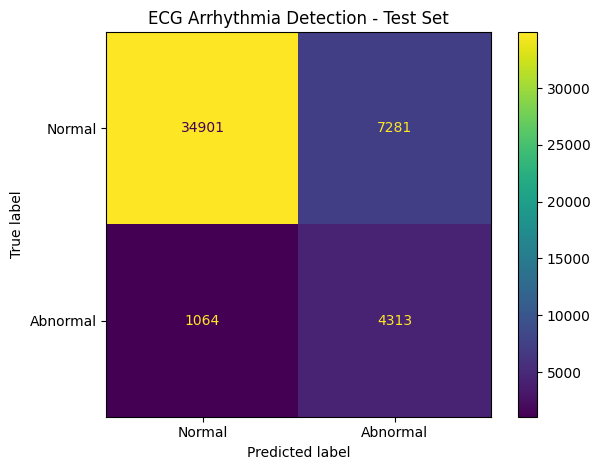

In [15]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(test_targets, test_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Abnormal"]
)

display.plot(values_format="d")
plt.title("ECG Arrhythmia Detection - Test Set")
plt.tight_layout()
plt.show()


Confusion matrix:
[[34901  7281]
 [ 1064  4313]]
True negatives:  34901
False positives: 7281
False negatives: 1064
True positives:  4313


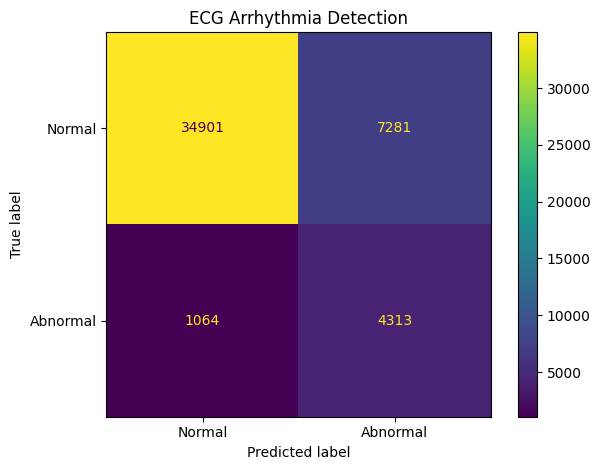

In [16]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Abnormal"]
).plot(values_format="d")

plt.title("ECG Arrhythmia Detection")
plt.tight_layout()
plt.show()


Improve the model by tuning the threshold

In [17]:

import numpy as np
import torch
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix
)

# Step A: Get abnormal probabilities on validation data
model.eval()
val_probs = []
val_true = []

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)
        logits = model(xb)

        # Probability of class 1 = abnormal
        probs = torch.softmax(logits, dim=1)[:, 1]

        val_probs.extend(probs.cpu().numpy())
        val_true.extend(yb.numpy())

val_probs = np.array(val_probs)
val_true = np.array(val_true)

# Step B: Find the threshold with the best validation F1
thresholds = np.arange(0.10, 0.91, 0.01)
best_threshold = 0.5
best_f1 = -1

for threshold in thresholds:
    val_pred = (val_probs >= threshold).astype(int)

    score = f1_score(
        val_true, val_pred,
        pos_label=1, zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best validation threshold:", round(best_threshold, 2))
print("Best validation F1-score:", round(best_f1, 4))

# Step C: Evaluate the chosen threshold on test data
test_probs = []
test_true = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        probs = torch.softmax(model(xb), dim=1)[:, 1]

        test_probs.extend(probs.cpu().numpy())
        test_true.extend(yb.numpy())

test_probs = np.array(test_probs)
test_true = np.array(test_true)

test_pred_tuned = (
    test_probs >= best_threshold
).astype(int)

print("\nTEST RESULTS WITH TUNED THRESHOLD")
print(f"Accuracy:  {accuracy_score(test_true, test_pred_tuned):.4f}")
print(f"Precision: {precision_score(test_true, test_pred_tuned, zero_division=0):.4f}")
print(f"Recall:    {recall_score(test_true, test_pred_tuned, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(test_true, test_pred_tuned, zero_division=0):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(test_true, test_pred_tuned, labels=[0, 1]))


Best validation threshold: 0.86
Best validation F1-score: 0.5003

TEST RESULTS WITH TUNED THRESHOLD
Accuracy:  0.9250
Precision: 0.7365
Recall:    0.5245
F1-score:  0.6126

Confusion matrix:
[[41173  1009]
 [ 2557  2820]]


In [19]:
# Configure your Git credentials
!git config --global user.email "surajguptacr7@gmail.com"
!git config --global user.name "surajguptacr7"

# Clone your repository using your GitHub Personal Access Token
!git clone https://<surajguptacr7>:<your-personal-access-token>@github.com/<surajguptacr7>/<MLProject>.git

# Move your notebook file into the cloned folder path, then stage, commit, and push
%cd <your-repo-name>
!git add .
!git commit -m "Added Colab notebook via command line"
!git push


/bin/bash: line 1: surajguptacr7: No such file or directory
[Errno 2] No such file or directory: '<your-repo-name>'
/content
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
